###  Python面向对象编程
- 到底什么是类，对象呢？（Class & Object）
- 封装、继承、多态

1️⃣类与对象基本概念
- **类（class）**：描述对象的模板（属性 + 方法）。
- **对象 / 实例（instance）**：由类创建的具体实体。
- **方法**：定义在类中的函数，第一个参数通常是 `self`，代表实例自身。
- **构造函数**：`__init__(...)` 用来初始化实例状态（属性）。

In [ ]:
## 1. 简单类定义

class Student:
    def __init__(self, age, sex):
        self.age = age
        self.sex = sex
    
    def speaking(self):
        print('苟利国家生死以')

    def thinking(self):
        print('我思故我在')

解析
- `__init__`：构造函数，在 `Student(...)` 创建实例时自动执行，通常用于给实例绑定属性 `self.age`、`self.sex`。
- `self`：实例自身的引用，用于访问或设置实例属性。
- `speaking` / `thinking`：普通实例方法，通过 `实例.方法()` 调用，隐含传入 `self`。


In [ ]:
## 2. 创建对象并调用方法

xiaoming = Student(18,'M')  # 创建Student对象
xiaoming.thinking() #等价于Student.thinking(xiaoming) # 调用方法
xiaoming.speaking()

2️⃣ 封装、继承与多态<br>

In [ ]:
## 子类继承父类
class Sjtuer(Student):
    def __init__(self, age, sex):
        super().__init__(age, sex)
        pass
    
    # 方法重写（多态）
    def speaking(self):
        print('苟利国家生死以')
    
    # 运算符重载（多态）
    def __add__(self,other):
        return self.age + other.age

    # 使对象可调用（多态）
    def __call__(self):
        return f'我是一个{self.age}岁的{self.sex}人'

In [ ]:
# 使用示例
xiaohong = Sjtuer(28,'F')
xiaolv = Sjtuer(18,'M')


✨ **了解什么是魔法方法**

In [ ]:
# 调用__add__ 重载的 + 运算符  
print(xiaohong + xiaolv)

# 调用__call__ 像函数一样调用对象  
print(xiaohong())

### tensor
- 有了array为何还要有个叫做tensor的东西？
    - **GPU 加速**：Tensor（PyTorch 的 `torch.Tensor`）能直接在 GPU（CUDA）上存储和计算，极大提升大规模矩阵运算速度。
    - **自动求导（Autograd）**：Tensor 可记录计算历史（计算图），自动求导，便于构建和训练神经网络。
    - **动态计算图**：PyTorch 使用动态图（eager execution），计算图在前向执行时即时构建，调试友好。

📊 Numpy 与 PyTorch Tensor基本特性对比

| 特性 | NumPy Array | PyTorch Tensor |优势 |
|------|-------|----------------|----------------|
| **运行设备** | 仅CPU | CPU + GPU + TPU |GPU 加速 |
| **自动求导** | ❌ 不支持 | ✅ 支持（autograd） |深度学习必备 |
| **动态计算图** | ❌ 无 | ✅ 支持 |灵活建模|
| **并行计算** | 有限支持 | ✅ GPU加速 |大规模运算|


In [3]:
import numpy as np
a1 = np.random.rand(1000,1000)
a2 = np.random.rand(1000,1000)
%timeit a1@a2

12.6 ms ± 580 µs per loop (mean ± std. dev. of 7 runs, 100 loops each)


In [ ]:
import torch
t1 = torch.rand(1000,1000).to('cuda')
t2 = torch.rand(1000,1000).to('cuda')
%timeit t1@t2

5.97 ms ± 136 µs per loop (mean ± std. dev. of 7 runs, 100 loops each)


###  自动求导

In [5]:
import torch
#from torchviz import make_dot
x = torch.tensor([1.0],requires_grad = True)#叶子节点
y = x** 2 + 2*x - 5
z = torch.sigmoid(y)
print(f'计算结果：{z}')
z.backward(retain_graph=True)
print(f'梯度值：{x.grad}')
print(f'z对x的梯度：{x.grad}')
#make_dot(z, params={'x': x})




计算结果：tensor([0.1192], grad_fn=<SigmoidBackward0>)
梯度值：tensor([0.4200])
z对x的梯度：tensor([0.4200])


<div style="background-color: #e0f0ff; border-left: 6px solid #366fa4; padding: 10px; border-radius: 4px; font-size: 1.2em; text-align: center;">
以下内容可根据需要选择性阅读
</div>

### 计算图

In [ ]:
import torch   
import torch.nn as nn
import torch.optim as optim

x = torch.tensor([1.0,2.0,3.0])
y_label = torch.tensor([2.1,4.1,6.05])

w = torch.tensor([1.0], requires_grad=True)
b = torch.tensor([1.0], requires_grad=True)

optimizer = optim.SGD([w,b], lr=0.1)

epochs = 150
lr = 0.1
for epoch in range(epochs):
    y_pred = w*x + b

    loss = nn.MSELoss()(y_pred, y_label)

    loss.backward()
    
    # with torch.no_grad():#不会记录梯度，减少了资源的消耗
    #     w -= lr*w.grad
    #     b -= lr*b.grad
    #     w.grad.zero_()
    #     b.grad.zero_()
    optimizer.step()
    optimizer.zero_grad()
  
    if epoch % 10 == 0:
        print(f'Epoch {epoch}, Loss {loss.item()}')
        print(f'w: {w.item()}, b: {b.item()}')
    

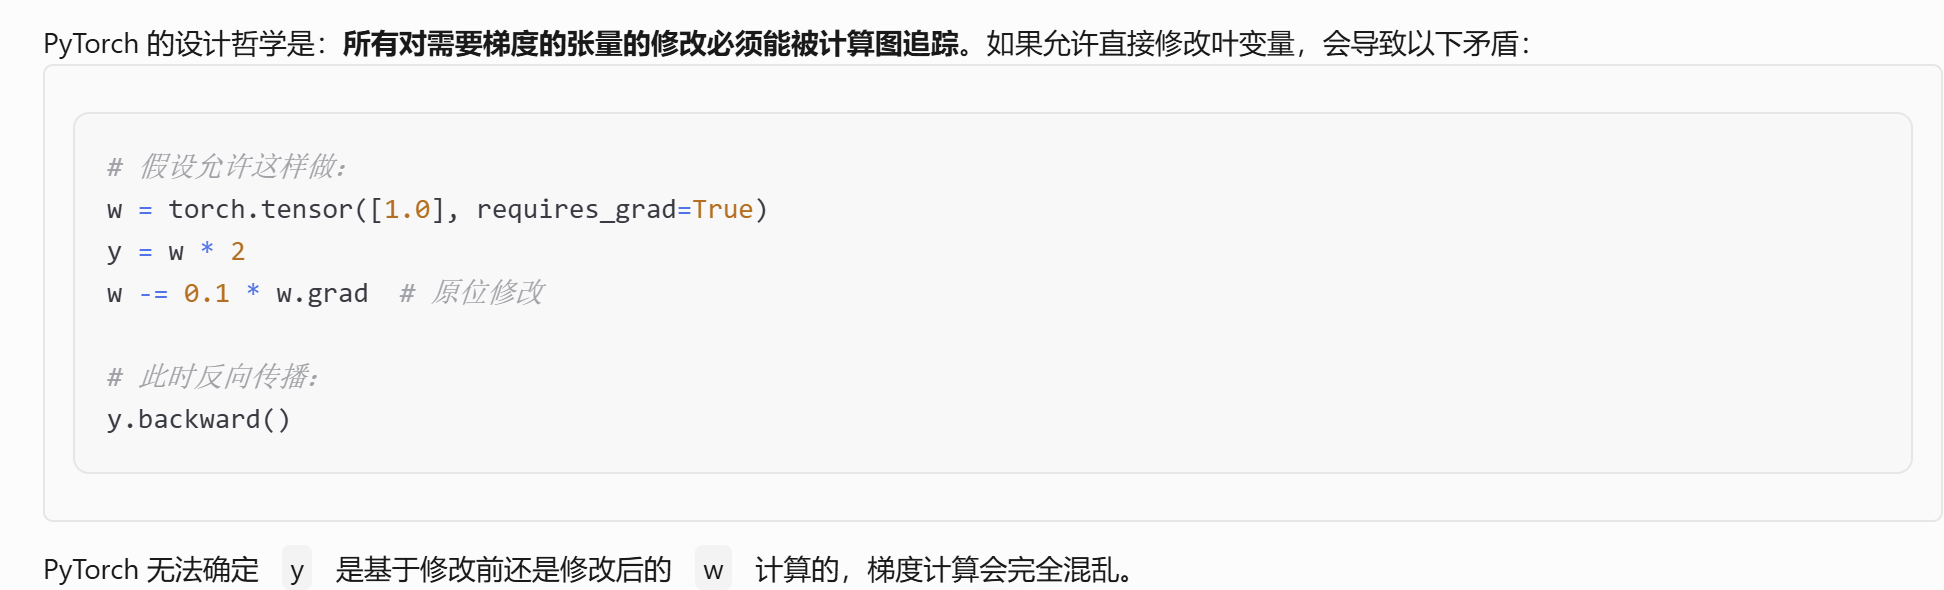

In [ ]:

w = torch.tensor([1.0], requires_grad=True)
b = torch.tensor([1.0], requires_grad=True)
x = torch.tensor([1.0,2.0,3.0])
y_label = torch.tensor([2.1,4.1,6.05])
y_pred = w*x + b

loss = nn.MSELoss()(y_pred, y_label)
loss.backward()
w.data -= 0.1 * w.grad
b.data  -= 0.1 * b.grad
make_dot(loss,params={w:w}).render("model_gra",format="png")
print(w,w.data)

### 如何理解计算图的一致性？
直接对叶子节点进行无保护的原地操作（如 w += 0.5 无 no_grad 包裹）会破坏计算图一致性，导致 RuntimeErro

In [ ]:
leaf = torch.tensor(1.0, requires_grad=False)#叶子节点，不记录梯度
w = torch.tensor(1.0, requires_grad=True) # 需要记录梯度的节点
y = w ** 2 + leaf   
z = 2 * w ** 3
y.backward()   
with torch.no_grad():
    w += 0.5   # 梯度计算基于 w=1.0 → grad=2.0此时修改后，w的version改为1
#w.data += 0.5          # 此时 w=1.5，但计算图仍记录 w=1.0
print(w.grad)
w.grad.zero_()
z.backward()#这个地方会报错，因为原来定义的时候z对应的w的version是0，现在w的version是1，所以会报错
w.grad

In [ ]:
import torch
import torch.nn as nn
from torchviz import make_dot
w = torch.tensor(1.0, requires_grad=True)
b = torch.tensor(1.0, requires_grad=True)
x = torch.tensor([1.0,2.0,3.0],requires_grad=True)
y = w * x + b
z = y.sum()
y.retain_grad()
z.backward()
make_dot(z, params={"w": w, "b": b, "x": x, "y": y}).render("graph0315", format="png")
print(w.is_leaf, b.is_leaf, x.is_leaf, y.is_leaf, z.is_leaf)